In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from pycbc.noise import noise_from_psd
from pycbc.psd import aLIGOZeroDetHighPower
from pycbc.types import TimeSeries
from scipy.signal import butter, sosfiltfilt

np.random.seed(42)

/home/gopal/miniconda3/envs/gwenv/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(True)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal


In [2]:
duration = 104.0       # seconds
fs = 2048              # Hz
dt = 1.0 / fs

# Total number of samples
N = int(duration * fs)

# Frequency resolution
delta_f = 1.0 / duration

# Band-pass frequencies
f_low = 30.0
f_high = 1000.0

print("Duration:", duration, "s")
print("Sampling frequency:", fs, "Hz")
print("Number of samples:", N)
print("delta_t:", dt, "s")
print("delta_f:", delta_f, "Hz")

Duration: 104.0 s
Sampling frequency: 2048 Hz
Number of samples: 212992
delta_t: 0.00048828125 s
delta_f: 0.009615384615384616 Hz


In [3]:
flen = N // 2 + 1
psd = aLIGOZeroDetHighPower(flen, delta_f, low_freq_cutoff=30.0)
freqs = np.arange(len(psd)) * delta_f
print("PSD length:", len(psd))
print("Maximum frequency:", freqs[-1], "Hz")

PSD length: 106497
Maximum frequency: 1024.0 Hz


In [4]:
h1_noise = noise_from_psd(N, dt, psd, seed=100)
l1_noise = noise_from_psd(N, dt, psd, seed=200)

print("H1 samples:", len(h1_noise))
print("L1 samples:", len(l1_noise))
print("H1 duration:", len(h1_noise) * dt, "s")
print("L1 duration:", len(l1_noise) * dt, "s")

H1 samples: 212992
L1 samples: 212992
H1 duration: 104.0 s
L1 duration: 104.0 s


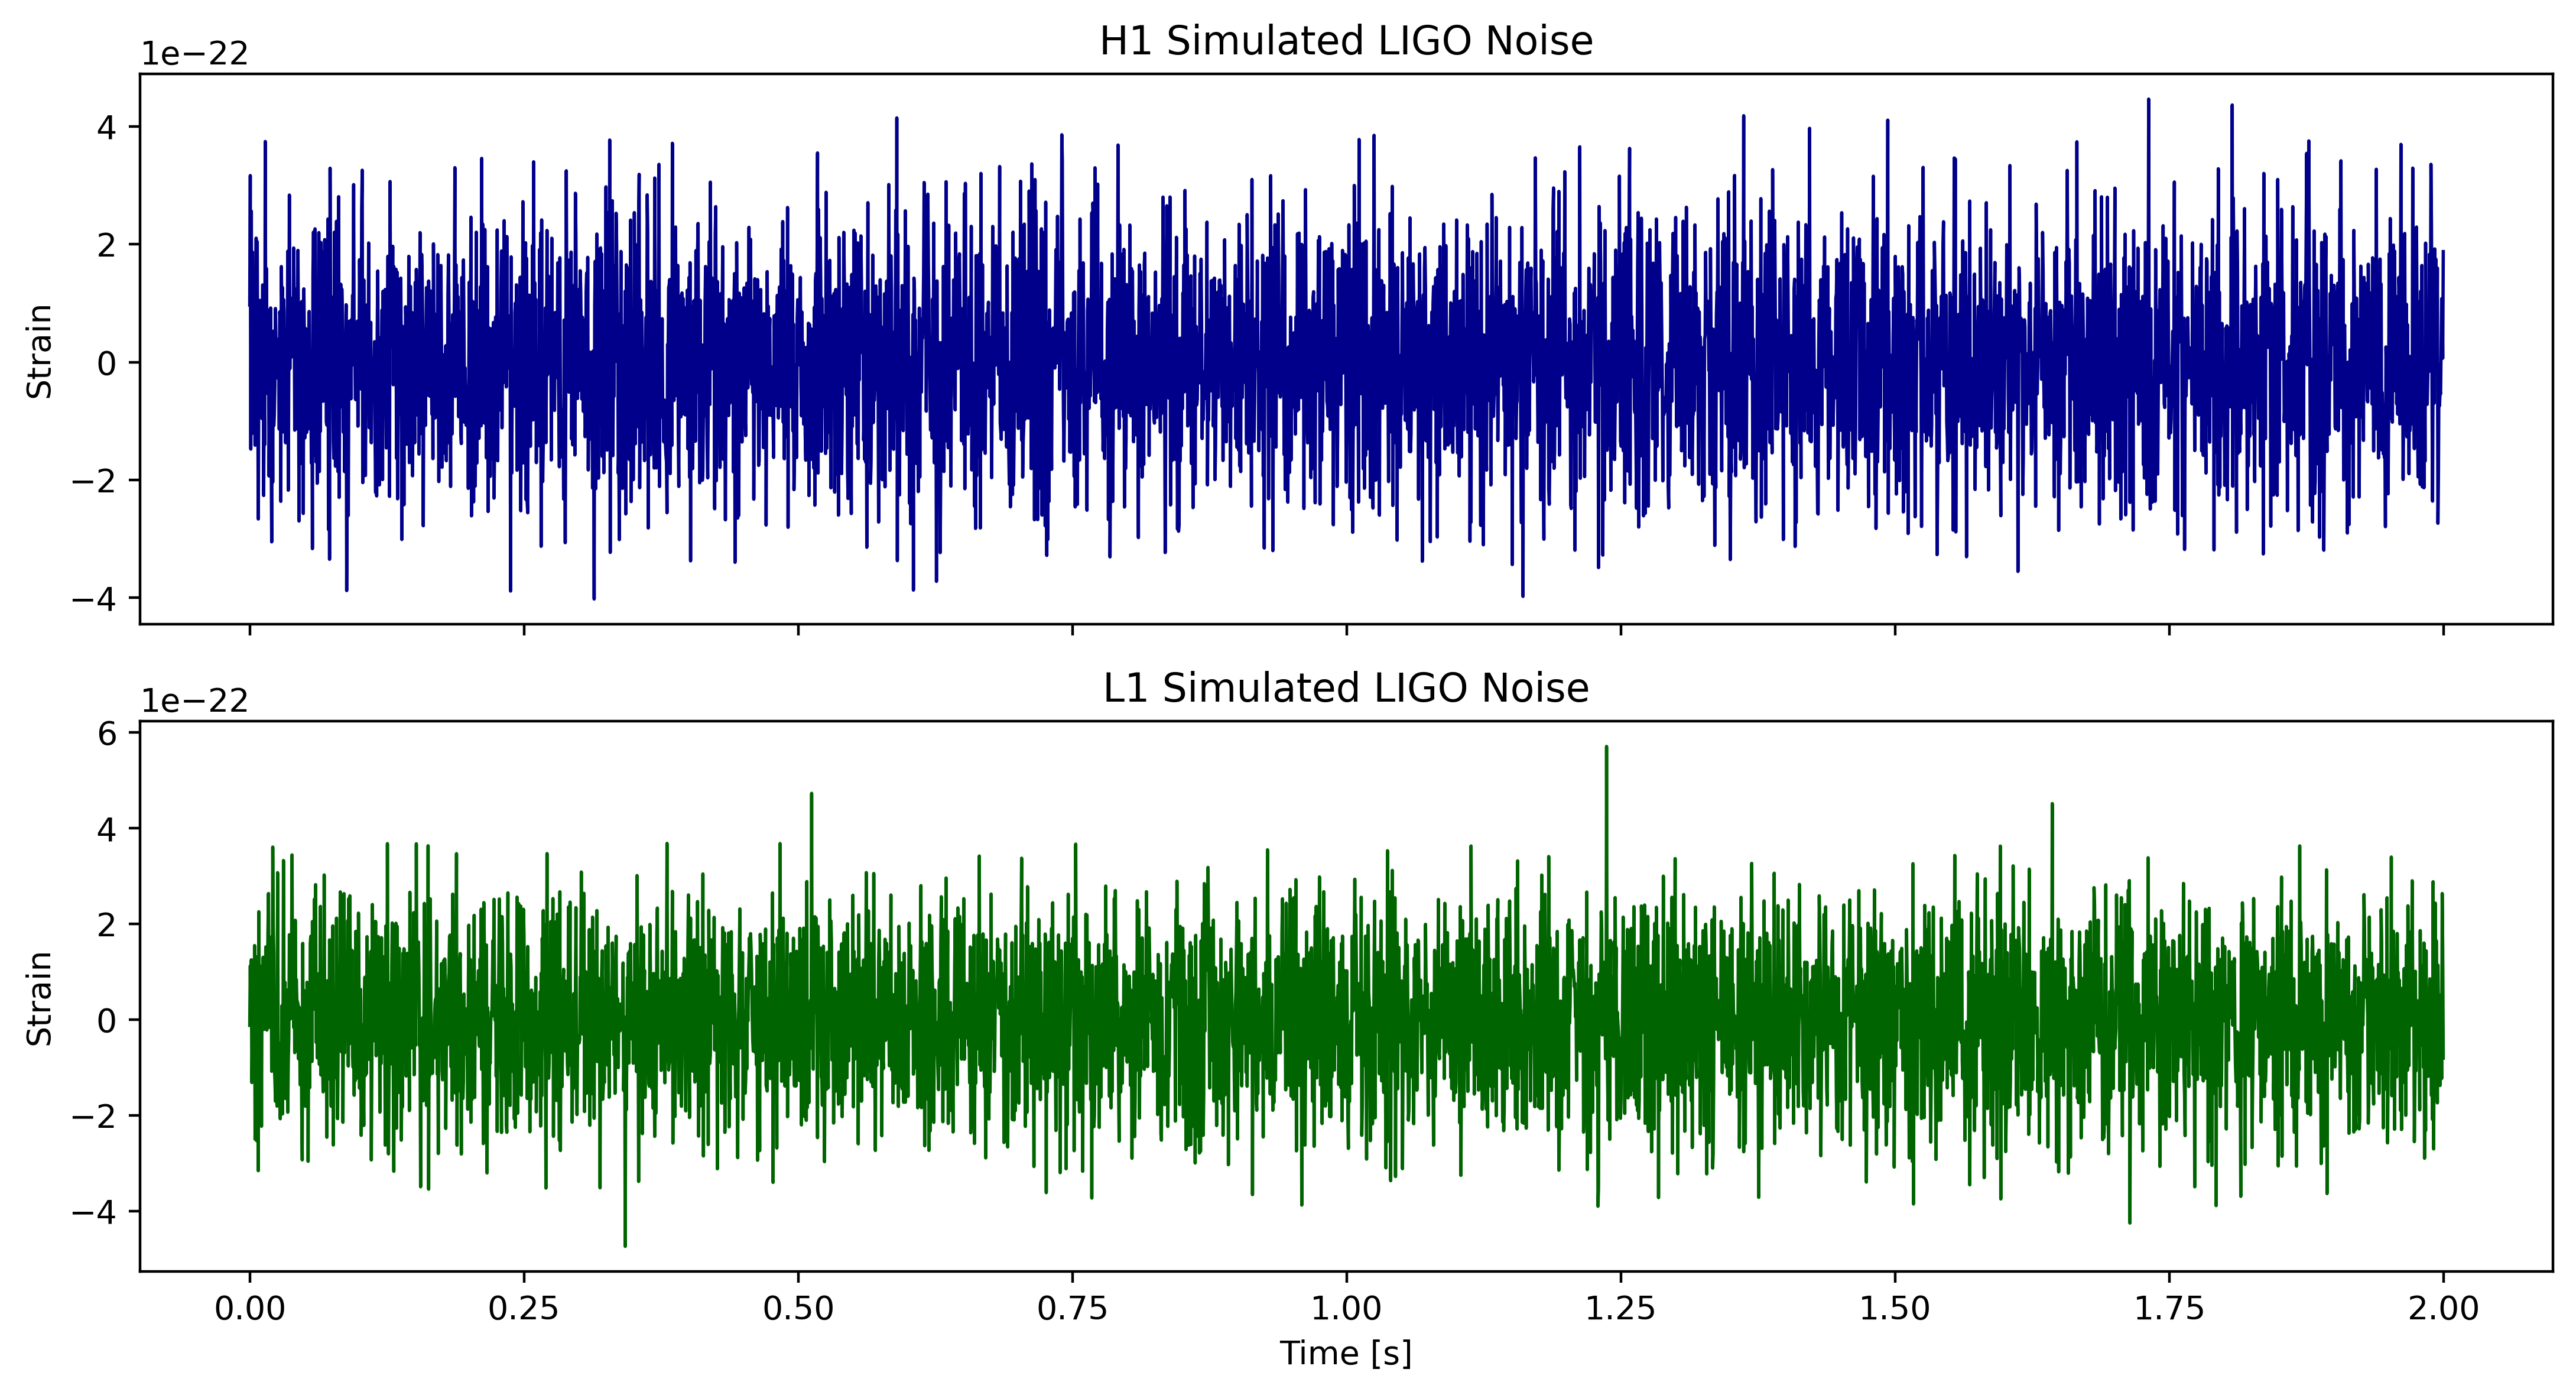

In [5]:
plot_duration = 2.0
nplot = int(plot_duration * fs)
time = np.arange(N) / fs
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, dpi = 400)

ax[0].plot(time[:nplot],h1_noise.numpy()[:nplot], color = "darkblue",linewidth= 1.0)
ax[0].set_ylabel("Strain")
ax[0].set_title("H1 Simulated LIGO Noise")
ax[1].plot(time[:nplot],l1_noise.numpy()[:nplot],color = "darkgreen",linewidth= 1.0)
ax[1].set_ylabel("Strain")
ax[1].set_xlabel("Time [s]")
ax[1].set_title("L1 Simulated LIGO Noise")

plt.tight_layout()
plt.show()

In [6]:
def whiten_with_psd(data, psd, fs):
    x = np.asarray(data, dtype=np.float64)

    N = len(x)
    dt = 1.0 / fs

    # FFT
    hf = np.fft.rfft(x)

    # PSD as numpy array
    psd_array = np.asarray(psd)

    # Avoid division by zero
    valid = psd_array > 0
    white_hf = np.zeros_like(hf, dtype=complex)

    # Whiten in frequency domain
    white_hf[valid] = hf[valid] / np.sqrt(psd_array[valid])

    # Back to time domain
    white = np.fft.irfft(white_hf, n=N)

    # Normalize scale
    white *= np.sqrt(2.0 * dt)

    return white

In [7]:
h1_whitened = whiten_with_psd(h1_noise.numpy(), psd, fs)
l1_whitened = whiten_with_psd(l1_noise.numpy(), psd, fs)

print("H1:", len(h1_whitened), "samples")
print("L1:", len(l1_whitened), "samples")
print("Duration:", len(h1_whitened) / fs, "s")

H1: 212992 samples
L1: 212992 samples
Duration: 104.0 s


In [8]:
def bandpass_filter(data, fs, lowcut=30.0, highcut=1000.0, order=4):
    sos = butter(order, [lowcut, highcut], btype="bandpass", fs=fs, output="sos")
    filtered = sosfiltfilt(sos, data)

    return filtered

In [9]:
h1_whitened_bp = bandpass_filter(h1_whitened, fs, lowcut=f_low,  highcut=f_high)
l1_whitened_bp = bandpass_filter(l1_whitened, fs, lowcut=f_low, highcut=f_high)

print("H1 final shape:", h1_whitened_bp.shape)
print("L1 final shape:", l1_whitened_bp.shape)
print("H1 duration:", len(h1_whitened_bp) / fs, "s")
print("L1 duration:", len(l1_whitened_bp) / fs, "s")

H1 final shape: (212992,)
L1 final shape: (212992,)
H1 duration: 104.0 s
L1 duration: 104.0 s


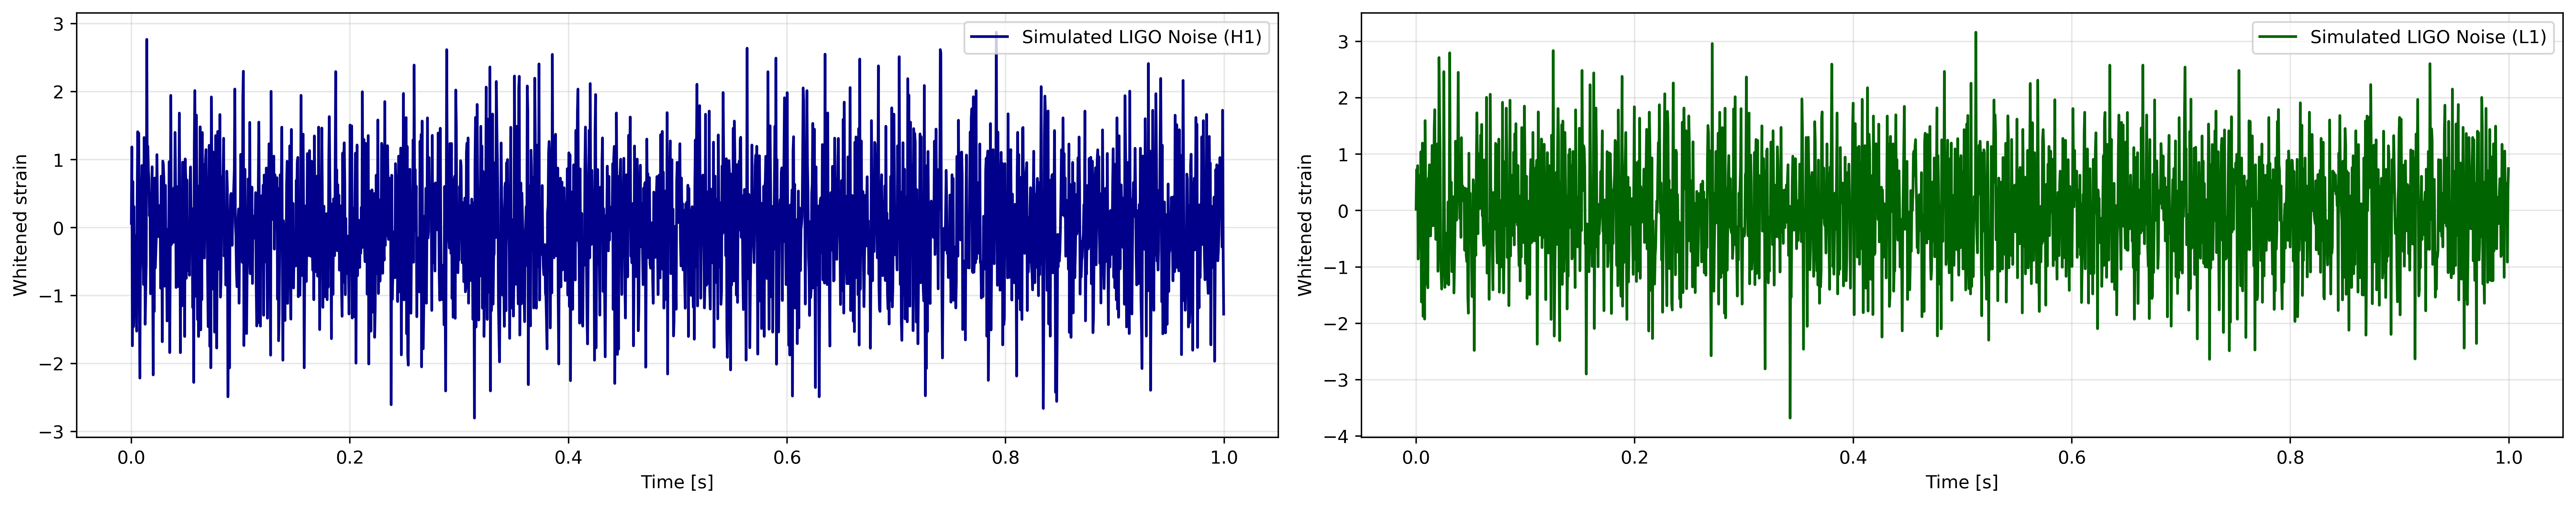

In [10]:
N = int(fs)                  # number of samples in 1 second
time_1s = np.arange(N) / fs  # time from 0 to 1 second

fig, axes = plt.subplots(1, 2, figsize=(20, 4), sharex=True, dpi=400)

# H1
axes[0].plot(
    time_1s,
    h1_whitened_bp[:N],
    linewidth=1.5,
    color="darkblue",
    label="Simulated LIGO Noise (H1)"
)
axes[0].set_xlabel("Time [s]")
axes[0].set_ylabel("Whitened strain")
axes[0].grid(alpha=0.3)
axes[0].legend(loc='upper right')

# L1
axes[1].plot(
    time_1s,
    l1_whitened_bp[:N],
    linewidth=1.5,
    color="darkgreen",
    label="Simulated LIGO Noise (L1)"
)
axes[1].set_xlabel("Time [s]")
axes[1].set_ylabel("Whitened strain")
axes[1].grid(alpha=0.3)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig('SimulatedLIGONoise_1s.png', dpi=400, bbox_inches='tight')
plt.show()

In [11]:
# Simple dot-product correlation between two arrays.
def cc(x, y):
    correlation = sum(a * b for a, b in zip(x, y))
    return correlation
    
# Cross-correlate two real detector data segments.
# data1: H1 segment
# data2: L1 segment
# times: time array for that segment

def cross_correlation_real_detector(data1, data2, times):
    data1 = data1 - np.mean(data1)
    data2 = data2 - np.mean(data2)

    correlations = []

    # Define lag range
    lags = np.arange(-len(times)//2, len(times)//2, 1)

    for lag in lags:
        data1_shifted = np.roll(data1, int(lag))

        correlation = cc(data1_shifted, data2)

        # Normalize by segment length
        correlation = correlation / len(times)

        correlations.append(correlation)

    correlations = np.array(correlations)

    return correlations, lags

In [12]:
# Remove first and last 2 seconds from 104 s data
# Then split the remaining 100 s into 100 one-second segments

num_files = 100

segment_duration = 1  # second
segment_samples = int(fs * segment_duration)  # 4096 samples

trim_duration = 2  # remove 2 seconds from both sides
trim_samples = int(fs * trim_duration)  # 8192 samples


# Keep only the middle 100 seconds
H1_middle = h1_whitened_bp[trim_samples : trim_samples + num_files * segment_samples]
L1_middle = l1_whitened_bp[trim_samples : trim_samples + num_files * segment_samples]

print("H1 middle-data shape:", H1_middle.shape)
print("L1 middle-data shape:", L1_middle.shape)

# Split middle 100 s into 100 one-second segments
h1_segments = []
l1_segments = []

for i in range(num_files):

    start_idx = i * segment_samples
    end_idx = start_idx + segment_samples

    h1_seg = H1_middle[start_idx:end_idx]
    l1_seg = L1_middle[start_idx:end_idx]

    h1_segments.append(h1_seg)
    l1_segments.append(l1_seg)


# Convert lists into NumPy arrays
h1_segments = np.array(h1_segments)
l1_segments = np.array(l1_segments)

print("H1 segments shape:", h1_segments.shape)
print("L1 segments shape:", l1_segments.shape)

H1 middle-data shape: (204800,)
L1 middle-data shape: (204800,)
H1 segments shape: (100, 2048)
L1 segments shape: (100, 2048)


In [13]:
# Time array for one segment
times = np.arange(segment_samples) / fs

print("Time array shape:", times.shape)
print("Start time:", times[0])
print("End time:", times[-1])

Time array shape: (2048,)
Start time: 0.0
End time: 0.99951171875


In [17]:
# Build 100 training files

save_folder = "../TranAD_MGB/data/GW_sim_900_snr12_ng/train/"
os.makedirs(save_folder, exist_ok=True)

num_files = 100
fs = 2048
segment_samples = fs        # 2048 samples = 1 second
num_sections = 4
section_samples = segment_samples // num_sections   # 512 samples per section

# Store the maximum absolute cross-correlation from each file
maxccs = []

for i in range(num_files):

    # Take one complete 1-second noise-only H1 and L1 segment
    noise1 = np.asarray(h1_segments[i]).flatten()
    noise2 = np.asarray(l1_segments[i]).flatten()

    # Remove the mean
    noise1 = noise1 - np.mean(noise1)
    noise2 = noise2 - np.mean(noise2)

    # Time array for the complete 1-second segment
    times = np.arange(segment_samples) / fs

    # Split into four sections and cross-correlate each section separately
    cc_sections = []
    for k in range(num_sections):
        a = k * section_samples
        b = (k + 1) * section_samples

        cc_k, lags = cross_correlation_real_detector(noise1[a:b], noise2[a:b], times[a:b])
        cc_sections.append(np.asarray(cc_k).flatten())

    # Concatenate the four correlated sections (2048 samples in total)
    final_sig = np.concatenate(cc_sections)

    # Store the maximum absolute cross-correlation
    maxcc = np.max(np.abs(final_sig))
    maxccs.append(maxcc)

    # Save the training file
    filename = f"{i}_GW_sim_900_snr12_ng_train.txt"
    np.savetxt(os.path.join(save_folder, filename), final_sig)
    print(f"Saved training file: {i}")

# Convert the collected maximum values to an array
maxccs = np.asarray(maxccs)

print("\nDone.")
print("Number of training files:", num_files)
print("Length of each file:", len(final_sig))     

Saved training file: 0
Saved training file: 1
Saved training file: 2
Saved training file: 3
Saved training file: 4
Saved training file: 5
Saved training file: 6
Saved training file: 7
Saved training file: 8
Saved training file: 9
Saved training file: 10
Saved training file: 11
Saved training file: 12
Saved training file: 13
Saved training file: 14
Saved training file: 15
Saved training file: 16
Saved training file: 17
Saved training file: 18
Saved training file: 19
Saved training file: 20
Saved training file: 21
Saved training file: 22
Saved training file: 23
Saved training file: 24
Saved training file: 25
Saved training file: 26
Saved training file: 27
Saved training file: 28
Saved training file: 29
Saved training file: 30
Saved training file: 31
Saved training file: 32
Saved training file: 33
Saved training file: 34
Saved training file: 35
Saved training file: 36
Saved training file: 37
Saved training file: 38
Saved training file: 39
Saved training file: 40
Saved training file: 41
Sa

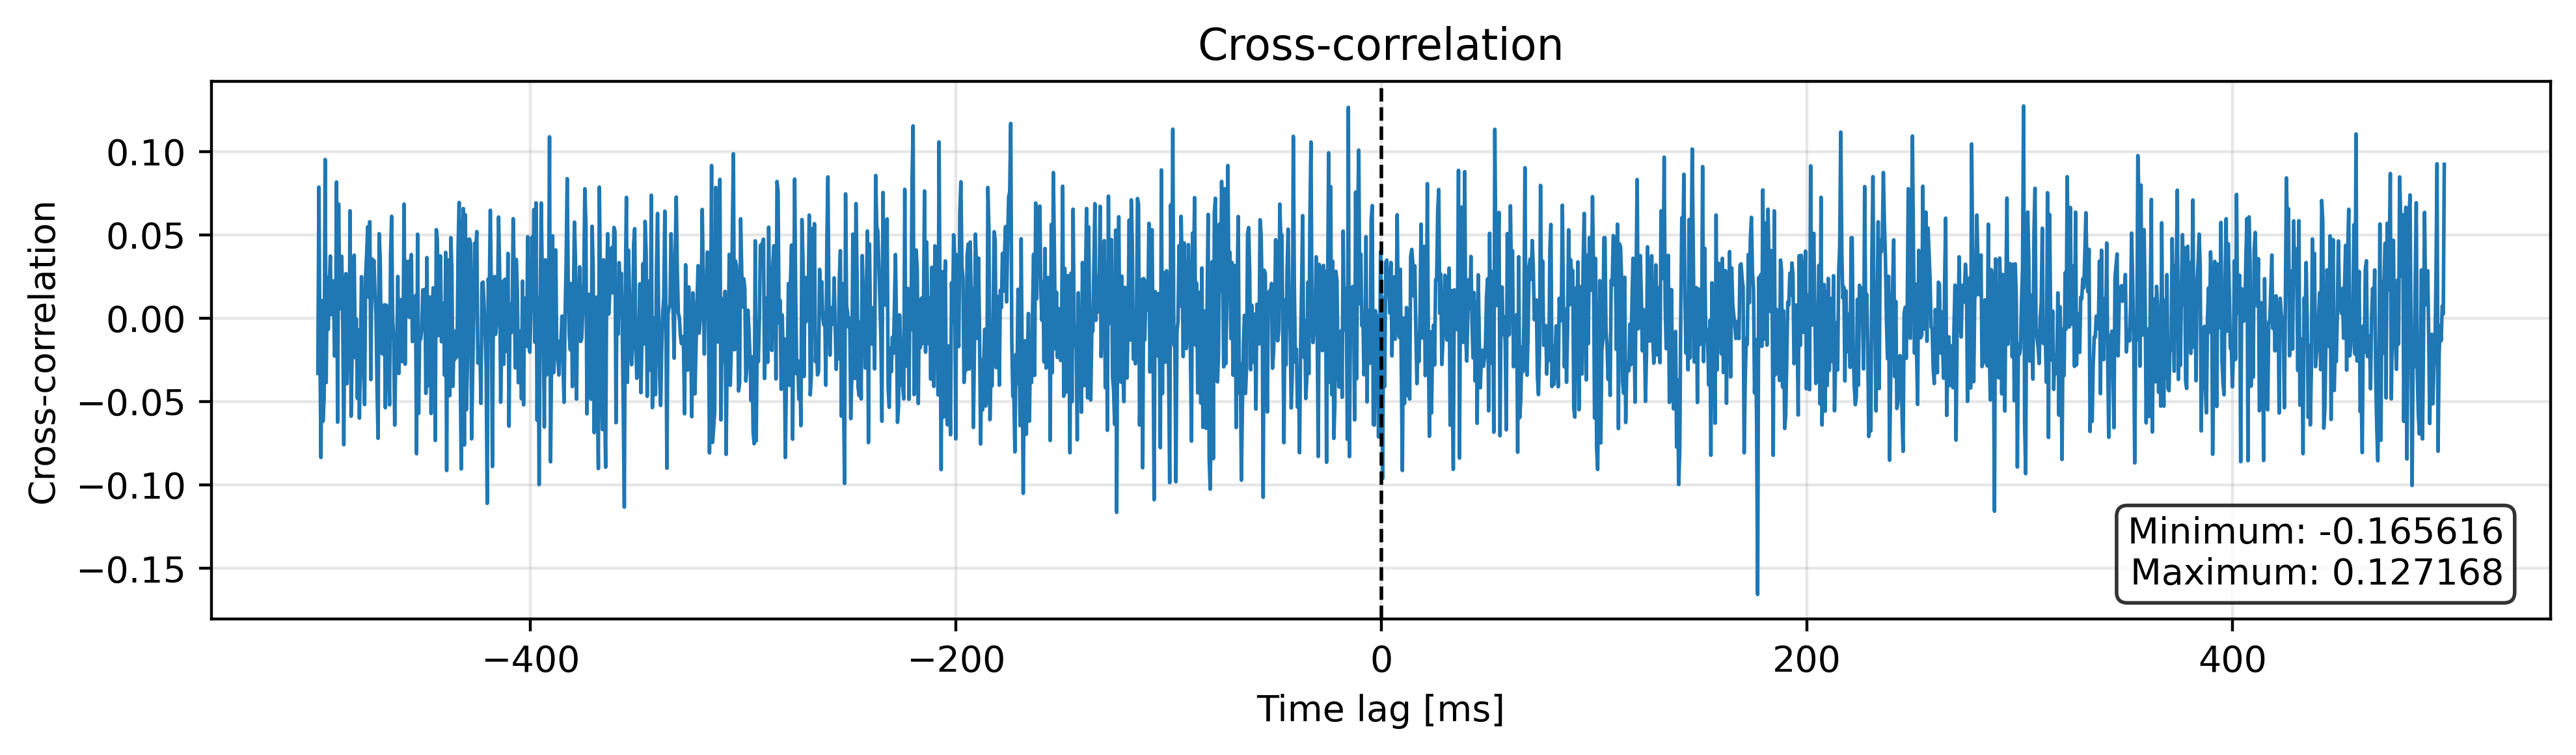

In [ ]:

signal_file_index = 10

train_file = (f"../TranAD_MGB/data/GW_sim_900_snr12_ng/train/"
              f"{signal_file_index}_GW_sim_900_snr12_ng_train.txt")
sample = np.loadtxt(train_file)

min_value = sample.min()
max_value = sample.max()

plt.figure(figsize=(10, 3), dpi=400)
plt.plot(np.arange(len(sample)), sample, linewidth=1.0)

# Section boundaries
for b in [512, 1024, 1536]:
    plt.axvline(b, color="gray", linestyle="--", linewidth=0.8)

plt.xlabel("Timestamp")
plt.ylabel("Cross-correlation")
plt.title("Cross-correlation (4 sections)")
plt.xlim(0, len(sample))

plt.text(0.98, 0.05, f"Minimum: {min_value:.6f}\nMaximum: {max_value:.6f}",
         transform=plt.gca().transAxes, horizontalalignment="right",
         verticalalignment="bottom", bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()